# Accès à l'électricité en Afrique de l'Ouest (2000-2024)
Qui progresse le plus vite ? Analyse de 10 pays à partir
des données de la Banque mondiale.

## 1. Chargement des données
Source : Banque mondiale, World Development Indicators,
indicateur « Access to electricity (% of population) ».

In [2]:

import pandas as pd

df= pd.read_csv("data/WB_WDI_EG_ELC_ACCS_ZS.csv")
df.shape

(8122, 41)

In [3]:
df.head()

,STRUCTURE,STRUCTURE_ID,ACTION,FREQ,REF_AREA,INDICATOR,SEX,AGE,URBANISATION,UNIT_MEASURE,...,COMP_BREAKDOWN_2_LABEL,COMP_BREAKDOWN_3_LABEL,AGG_METHOD_LABEL,UNIT_TYPE_LABEL,DECIMALS_LABEL,DATABASE_ID_LABEL,TIME_FORMAT_LABEL,UNIT_MULT_LABEL,OBS_STATUS_LABEL,OBS_CONF_LABEL
0,datastructure,WB.DATA360:DS_DATA360(1.4),I,A,VIR,WB_WDI_EG_ELC_ACCS_ZS,_T,_T,_T,PT_POP,...,Not Applicable,Not Applicable,Not Applicable,Ratio,Two,World Development Indicators (WDI),Annual,Units,Normal value,Public
1,datastructure,WB.DATA360:DS_DATA360(1.4),I,A,PSE,WB_WDI_EG_ELC_ACCS_ZS,_T,_T,_T,PT_POP,...,Not Applicable,Not Applicable,Not Applicable,Ratio,Two,World Development Indicators (WDI),Annual,Units,Normal value,Public
2,datastructure,WB.DATA360:DS_DATA360(1.4),I,A,YEM,WB_WDI_EG_ELC_ACCS_ZS,_T,_T,_T,PT_POP,...,Not Applicable,Not Applicable,Not Applicable,Ratio,Two,World Development Indicators (WDI),Annual,Units,Normal value,Public
3,datastructure,WB.DATA360:DS_DATA360(1.4),I,A,ZMB,WB_WDI_EG_ELC_ACCS_ZS,_T,_T,_T,PT_POP,...,Not Applicable,Not Applicable,Not Applicable,Ratio,Two,World Development Indicators (WDI),Annual,Units,Normal value,Public
4,datastructure,WB.DATA360:DS_DATA360(1.4),I,A,ZWE,WB_WDI_EG_ELC_ACCS_ZS,_T,_T,_T,PT_POP,...,Not Applicable,Not Applicable,Not Applicable,Ratio,Two,World Development Indicators (WDI),Annual,Units,Normal value,Public


In [4]:
df.columns

Index(['STRUCTURE', 'STRUCTURE_ID', 'ACTION', 'FREQ', 'REF_AREA', 'INDICATOR',
       'SEX', 'AGE', 'URBANISATION', 'UNIT_MEASURE', 'COMP_BREAKDOWN_1',
       'COMP_BREAKDOWN_2', 'COMP_BREAKDOWN_3', 'TIME_PERIOD', 'OBS_VALUE',
       'AGG_METHOD', 'UNIT_TYPE', 'DECIMALS', 'DATABASE_ID', 'TIME_FORMAT',
       'UNIT_MULT', 'OBS_STATUS', 'OBS_CONF', 'FREQ_LABEL', 'REF_AREA_LABEL',
       'INDICATOR_LABEL', 'SEX_LABEL', 'AGE_LABEL', 'URBANISATION_LABEL',
       'UNIT_MEASURE_LABEL', 'COMP_BREAKDOWN_1_LABEL',
       'COMP_BREAKDOWN_2_LABEL', 'COMP_BREAKDOWN_3_LABEL', 'AGG_METHOD_LABEL',
       'UNIT_TYPE_LABEL', 'DECIMALS_LABEL', 'DATABASE_ID_LABEL',
       'TIME_FORMAT_LABEL', 'UNIT_MULT_LABEL', 'OBS_STATUS_LABEL',
       'OBS_CONF_LABEL'],
      dtype='str')

## 2. Sélection des colonnes utiles

In [5]:

elec = df[["OBS_VALUE","REF_AREA","TIME_PERIOD","OBS_STATUS","REF_AREA_LABEL"]]

In [6]:
elec.shape

(8122, 5)

## 3. Filtrage des pays d'Afrique de l'Ouest

In [7]:
pays = ["CIV","SEN","GHA","NGA","BFA","MLI","NER","BEN","TGO","GIN"]
elec_ao = elec[elec["REF_AREA"].isin(pays)]

In [8]:
elec_ao.shape

(306, 5)

In [9]:
elec["TIME_PERIOD"].min(), elec["TIME_PERIOD"].max()

(np.int64(1990), np.int64(2024))

In [10]:
elec_ao.groupby("REF_AREA_LABEL")["TIME_PERIOD"].agg(["min","max","count"])

,min,max,count
REF_AREA_LABEL,,,
Benin,1996,2024,29
Burkina Faso,1993,2024,32
Côte d’Ivoire,1994,2024,31
Ghana,1993,2024,32
Guinea,1999,2024,26
Mali,1996,2024,29
Niger,1992,2024,33
Nigeria,1990,2024,35
Senegal,1993,2024,32


## 4. Choix d'une période commune
Les données ne commencent pas la même année selon les pays
(1990 pour le Nigeria, 1999 pour la Guinée). Pour comparer
équitablement, on garde la période 2000-2024.

In [11]:
elec_ao = elec_ao[elec_ao["TIME_PERIOD"] >= 2000]

In [12]:
elec_ao.shape

(250, 5)

## 5. Évolution de l'accès à l'électricité

In [13]:
tableau = elec_ao.pivot(index="TIME_PERIOD", columns="REF_AREA_LABEL", values="OBS_VALUE")

In [14]:
tableau.shape

(25, 10)

<Axes: xlabel='TIME_PERIOD'>

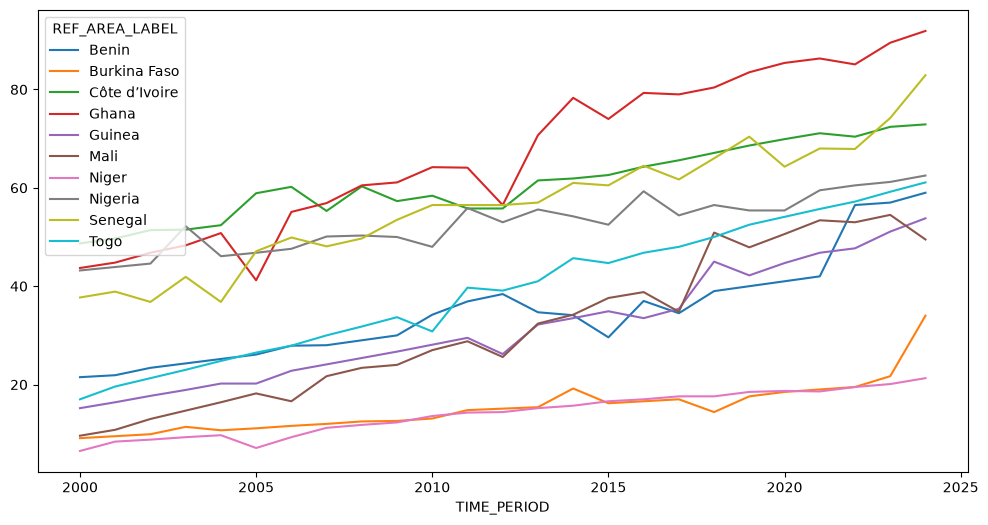

In [15]:
tableau.plot(figsize=(12,6)) 

## 6. Progression entre 2000 et 2024
La Côte d'Ivoire avait le meilleur niveau en 2000, mais
n'arrive qu'en 8e position pour la progression.

In [16]:
progression = tableau.loc[2024] - tableau.loc[2000]
progression.sort_values(ascending=False)

REF_AREA_LABEL
Ghana            48.2
Senegal          45.2
Togo             44.1
Mali             39.9
Guinea           38.6
Benin            37.5
Burkina Faso     24.9
Côte d’Ivoire    24.2
Nigeria          19.3
Niger            14.8
dtype: float64